## 1D Heat Equation
    
$$ u_t=0.003u_{xx} $$
\
\
$$BC$$
$$u(0,t)=u(1,t)=0$$
\
\
$$IC$$
$$u(x,0)=50x(1-x)$$ $$for$$ $$0<x<1$$

## Importing Libraries

In [85]:
# Import torch libraries
import torch 
import torch.autograd as autograd # helps in to find gradient (automatic gradient)
from torch import Tensor          # helps to convert the matrix to torch
import torch.nn as nn             # Neural network
import torch.optim as optim       # Optimization

# Libraries for ploting
import matplotlib.pyplot as plt
import scipy.io


import numpy as np  # Numpy 
import math         # Math
import time         # time

# library for generating residual points
from pyDOE import lhs

# libraries for saving datafiles
from numpy import asarray
from numpy import savetxt

## Set seed values for Random number generation

In [86]:
# Random number 
torch.set_default_dtype(torch.float)
torch.manual_seed(987)
np.random.seed(987)

## Check for device='GPU'

In [87]:
torch.cuda.empty_cache() # Empty the cache memory
device=torch.cuda.get_device_name()  # Save the device name of gpu
print("- Original device name:- ", device)

device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    
print("- Now device name is:- ", device)

- Original device name:-  NVIDIA GeForce RTX 3060 Laptop GPU
- Now device name is:-  cuda


## Generating the coordinates

In [88]:
data_x=np.linspace(0,1,200)    # Generate data x (position) from 0 to 1 (200 equidistance points)
data_t=np.linspace(0,8,100)    # Generate data t (time) from 0 to 8s (100 equitime interval)

# Generate meshgrid for x and t coordinates
X,T=np.meshgrid(data_x,data_t)

# Flatten the grid structure to a matrix of size [ 200*100 X 2 ]
X_u_test=np.hstack((X.flatten()[:,None],T.flatten()[:,None]))

# Convert the X_u_test data tensor (for calculation in PyTorch)
X_u_test_tensor=torch.from_numpy(X_u_test).float().to(device)

- Setting up the upper and lower limit from the data, for feature scaling

In [89]:
lb=X_u_test[0]    # Lower limit
ub=X_u_test[-1]   # Upper limit
print(lb,ub)

[0. 0.] [1. 8.]


## Initial Condition

In [90]:
#initial condition
initial_condition=np.hstack((X[0,:][:,None],T[0,:][:,None])) # Considereing initial values

initial_condition_u=[]   

# Loop for calculation
for i in data_x:
    initial_condition_u.append(50*i*(1-i))

# converting the list to array
initial_condition_u=np.array(initial_condition_u)
initial_condition_u=initial_condition_u[:,None]   # flatten in this format: [:,None]

## Boundary condition

In [91]:
# Boundary condition
#1
boundary_condition1=np.hstack((X[:,0][:,None],T[:,0][:,None]))
boundary_condition1_u=np.zeros((len(boundary_condition1),1),order="F")

#2
boundary_condition2=np.hstack((X[:,-1][:,None],T[:,-1][:,None]))
boundary_condition2_u=np.zeros((len(boundary_condition2),1),order="F")

- Stack the initial condition and both the boundary condition

In [92]:
all_x_train=np.vstack([initial_condition,boundary_condition1,boundary_condition2])
#print(all_x_train)

all_u_train=np.vstack([initial_condition_u,boundary_condition1_u,boundary_condition2_u])
#print(all_u_train)

- N_u $\to$ Number of point selected from initial and Boundary (all_x_train)
- N_f $\to$ Number of points randomly generated inside the domain. (lhs is used $\to$ lathin hypercube sampling)

In [93]:
N_u=200
N_f=1000

idx=np.random.choice(all_x_train.shape[0],N_u,replace=False)
#print(idx)

# number of N_u are considered (Random values are selected based on idx)
X_u_train=all_x_train[idx,:]
u_train=all_u_train[idx,:]

In [94]:
X_f_train=lb+(ub-lb)*lhs(2,N_f) # lathin hypercube sampling 
# random number of N_f points are generated in 2D

#print(X_f_train)

'''
 Vertically stack the random points inside the domain(X_f_train) 
 and 
 the points of initial and boudnary condition(X_u_train)
'''

X_f_train=np.vstack((X_f_train,X_u_train))
#print(X_f_train)
print((X_f_train.shape))
print(type(X_f_train))

(1200, 2)
<class 'numpy.ndarray'>


## Plotting the random points and boundary/Initial points

(1200, 2)
(200, 2)


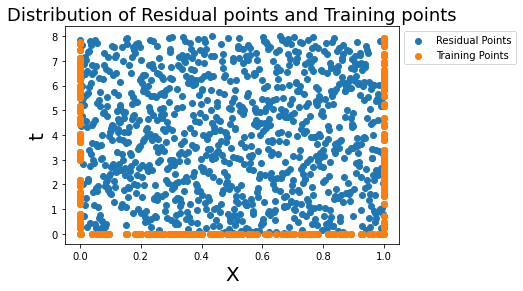

Size of X_u_train: (200, 2) 
Size of u_train: (200, 1) 
Size of X_f_train: (1200, 2)


In [95]:
plt.scatter(X_f_train[:,0],X_f_train[:,1],label="Residual Points")
plt.scatter(X_u_train[:,0],X_u_train[:,1],label="Training Points")

print(X_f_train.shape)
print(X_u_train.shape)
#savetxt('X_f_train',X_f_train,delimiter=',')
#savetxt('X_u_train',X_u_train,delimiter=',')

plt.xlabel("X",size=20)
plt.ylabel("t",size=20)
plt.legend(bbox_to_anchor =(1, 1))
plt.title("Distribution of Residual points and Training points",size=18)

plt.show()

# Printing the number of data points considered at boundary/initial with its actual values at boudnary/Initial
# Printing the numher of random data points considered inside the domain.        
print("Size of X_u_train:", X_u_train.shape,"\nSize of u_train:",u_train.shape,"\nSize of X_f_train:",X_f_train.shape)

## Convert the data into tensor

In [96]:
X_f_train=torch.from_numpy(X_f_train).float().to(device)
X_u_train=torch.from_numpy(X_u_train).float().to(device)
u_train=torch.from_numpy(u_train).float().to(device)
f_hat=torch.zeros(X_f_train.shape[0],1).to(device)

## PINN Class

In [97]:
class PINN(nn.Module):
    
    def __init__(self,layers):
        super().__init__()
        # Define the activation function
        self.activation=nn.Tanh()
        
        # Define the loss function used (Mean square Loss)
        self.loss_function=nn.MSELoss(reduction="mean")
        
        # Linear List for data storage
        self.linears=nn.ModuleList([nn.Linear(layers[i],layers[i+1])for i in range(len(layers)-1)])
        
        # iter for counting purpose
        self.iter=0
        
        # Setting initial values of weight and bias
        for i in range(len(layers)-1):
            nn.init.xavier_normal_(self.linears[i].weight.data,gain=1.0) # Weights as Xavier normal
            nn.init.zeros_(self.linears[i].bias.data)     # Bias as zero
     
    # Forward Pass
    def forward(self,x):
        
        # Check for torch if not then convert
        if torch.is_tensor(x)!=True:
            x=torch.from_numpy(x)
            
        # Convert lower and upper limit values to torch
        u_b=torch.from_numpy(ub).float().to(device)
        l_b=torch.from_numpy(lb).float().to(device)
        
        # Feature scaling
        x=(x-l_b)/(u_b-l_b)
        a=x.float()
        
        # Forward Pass
        for i in range(len(layers)-2):
            z=self.linears[i](a)  # Linear product  (Wt.X)
            a=self.activation(z)  # Passing by activation function f(Wt.X)
        
        # Considere the last layer with unit activation function
        a=self.linears[-1](a)
        
        return a
    
    # Loss function for Boundary and Initial Condition
    def loss_BC(self,x,y):
        
        loss_u=self.loss_function(self.forward(x),y) # MSE loss for U_pred and U_True
        
        return loss_u
    
    # Loss function for Domain + Boundary/Initial Points (PDE Loss)
    def loss_PDE(self,x_to_train_f):
        
        K=0.003 # As per equation
        
        # Create clone
        g=x_to_train_f.clone()
        g.requires_grad=True # Requires grad to be true
        
        # Forward Pass
        u=self.forward(g)
        
        # Calculating Gradient of U
        u_x_t=autograd.grad(u,g,torch.ones([x_to_train_f.shape[0],1]).to(device),retain_graph=True,create_graph=True)[0]
        u_xx_tt=autograd.grad(u_x_t,g,torch.ones(x_to_train_f.shape).to(device),create_graph=True)[0]
        
        # Seperate the gradient
        u_x=u_x_t[:,[0]]
        u_t=u_x_t[:,[1]]
        
        u_xx=u_xx_tt[:,[0]]
        
        ######
        # Partial Differential Equation
        f=u_t-K*u_xx
        ######
        
        # MSE Loss function for PDE and Zeros. 
        loss_f=self.loss_function(f,f_hat)
        
        return loss_f
    
    # Loss function which calls the Loss_BC and Loss_PDE and return SUM OF BOTH THE LOSS
    def loss(self,x,y,x_to_train_f):
        
        # loss_u= boundary and initial condition loss
        loss_u=self.loss_BC(x,y)
        # loss_f= loss of partial differential equation
        loss_f=self.loss_PDE(x_to_train_f)
        
        loss_val=loss_u+loss_f # Sum of Both the Loss
        
        # Saving the data file
        #file1=open('BC_LOSS_HEAT_transfer_problem_1.txt','a')
        #file1.write(str(loss_u.item())+'\n')
        #file1.close()
        
        #file1=open('PDE_LOSS_HEAT_transfer_problem_1.txt','a')
        #file1.write(str(loss_f.item())+'\n')
        #file1.close()
        
        #file3=open('TOTAL_LOSS_HEAT_transfer_problem_1.txt','a')
        #file3.write(str(loss_val.item())+'\n')
        #file3.close()
        
        return loss_val
    
    # Closure Function
    def closure(self):
        # Considereing zero grad after every step
        optimizer.zero_grad()
        
        # Call the loss function 
        loss=self.loss(X_u_train,u_train,X_f_train)
        
        loss.backward() # Backward Prop.
        
        self.iter+=1 # Counting iterations
        
        #file1=open('LOSS_HEAT_transfer_problem.txt','a')
        #file1.write(str(loss.item())+'\n')
        #file1.close()
        
        # Print the Total Loss per 100 iteration 
        if self.iter%100==0:
            print(loss)
        return loss
    
    # Test function returns the predicted the velocity (U_pred) 
    def test(self):
        
        u_pred=self.forward(X_u_test_tensor)
        u_pred=u_pred.detach().cpu().numpy() # Taking the values from cuda to the device
        
        u_pred=np.reshape(u_pred,(20000,1),order="F") ## Reshaping the values
        
        # Return predicted values
        return u_pred
    
    
        

## MAIN Function

In [98]:
layers=np.array([2,40,40,40,40,1]) # Define the Number of neurons per layer

# Create Object passing Layers information to class PINN 
H=PINN(layers)
H.to(device)

print(H) # Print Information of PINN 

params=list(H.parameters())

# Optimization by LBFGS 
optimizer=torch.optim.LBFGS(H.parameters(),lr=0.01,max_iter=10000,tolerance_grad=1e-15,
                            tolerance_change=1e-09,history_size=100)


# Calculating the Time
start_time=time.time()
optimizer.step(H.closure) # Update the weights and bias terms
elapsed=time.time()-start_time

# Print the time for training
print("\nTraining Time:",elapsed)

PINN(
  (activation): Tanh()
  (loss_function): MSELoss()
  (linears): ModuleList(
    (0): Linear(in_features=2, out_features=40, bias=True)
    (1): Linear(in_features=40, out_features=40, bias=True)
    (2): Linear(in_features=40, out_features=40, bias=True)
    (3): Linear(in_features=40, out_features=40, bias=True)
    (4): Linear(in_features=40, out_features=1, bias=True)
  )
)
tensor(10.5352, device='cuda:0', grad_fn=<AddBackward0>)
tensor(4.4342, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.2408, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0498, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0128, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0044, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0019, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0010, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0005, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0003, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0003, device='cuda:0', grad_fn=<AddBackward

## Print Plots

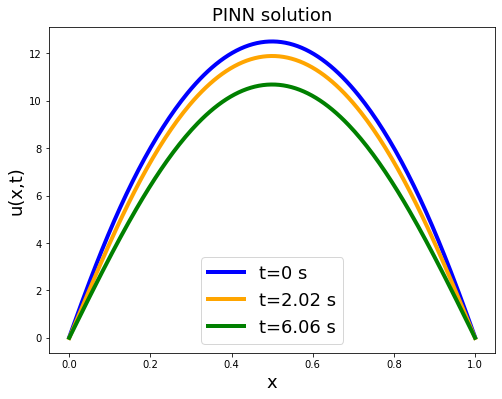

In [99]:
# Figure
ax=plt.figure(figsize=(8,6))

# T=0
u_val_t0=[]
x_value_t0=X_u_test[0:200]
x_value_0=x_value_t0[:,0]
u_pred=H.test()
u_value_t0=u_pred[0:200,[0]]

#print(u_value_t0)
#savetxt('x_value_0',x_value_0,delimiter=',')
#savetxt('u_value_t0',u_value_t0,delimiter=',')

plt.plot(x_value_0,u_value_t0,label="t=0 s",linewidth="4",color="b")
##------------------##-----------------------------##----------------------##

# T=2
x_value_t2=X_u_test[5000:5200]
#print(x_value_t2)
x_value_2=x_value_t2[:,0]
#print(x_value_2)
u_value_t2=u_pred[5000:5200,[0]]
plt.plot(x_value_2,u_value_t2,label="t=2.02 s",linewidth="4",color="orange")
#savetxt('x_value_2',x_value_2,delimiter=',')
#savetxt('u_value_t2',u_value_t2,delimiter=',')
##------------------##-----------------------------##----------------------##

#T=6
x_value_t6=X_u_test[15000:15200]
#print(x_value_t6)
x_value_6=x_value_t6[:,0]
u_value_t6=u_pred[15000:15200,[0]]
plt.plot(x_value_6,u_value_t6,label="t=6.06 s",linewidth="4",color="green")
#savetxt('x_value_6',x_value_6,delimiter=',')
#savetxt('u_value_t6',u_value_t6,delimiter=',')
##------------------##-----------------------------##----------------------##


plt.xlabel("x",fontsize=18)
plt.ylabel("u(x,t)",fontsize=18)
plt.legend(fontsize=18)
plt.title("PINN solution",size=18)
plt.show()


## Exact solution
Solution by seperation of variables
\
\
$f(x)=\sum_{n=1}^{inf} b_n sin(n \pi x)$


where $b_n$ can be defined as,


$b_n={\frac{400}{\pi^3 n^3}}$ if n is odd
\
$b_n=0$ if n is even

In [100]:
N=np.linspace(1,100,100)
#print(N)
n=[]
for i in N:
    if i%2!=0:
        n.append(i)
#print(n)

# for t=0
u0=[]

for j in data_x:
    A=0
    for i in n:
        A+=(400*math.sin(i*math.pi*j)*(math.exp(-((i**2)*(math.pi**2)*0.003*0))))/(math.pi*math.pi*math.pi*i*i*i)
    u0.append(A)
#print(u0)
##------------------##-----------------------------##----------------------##

u2=[]
for j in data_x:
    A=0
    for i in n:
        A+=(400*math.sin(i*math.pi*j)*(math.exp(-((i**2)*(math.pi**2)*0.003*2.0202))))/(math.pi*math.pi*math.pi*i*i*i)
    u2.append(A)
#print(u2)
##------------------##-----------------------------##----------------------##

u6=[]
for j in data_x:
    A=0
    for i in n:
        A+=(400*math.sin(i*math.pi*j)*(math.exp(-((i**2)*(math.pi**2)*0.003*6.0606))))/(math.pi*math.pi*math.pi*i*i*i)
    u6.append(A)
#print(u6)

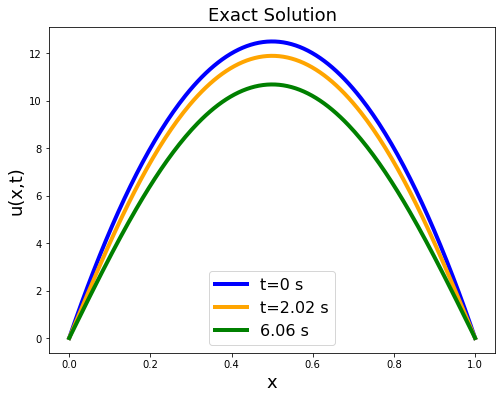

In [101]:
ax=plt.figure(figsize=(8,6))
plt.plot(data_x,u0,label="t=0 s",linewidth="4",color="b")
plt.plot(data_x,u2,label="t=2.02 s",linewidth="4",color="orange")
plt.plot(data_x,u6,label="6.06 s",linewidth="4",color="green")

#savetxt('data_x',data_x,delimiter=',')
#savetxt('u0',u0,delimiter=',')
#savetxt('u2',u2,delimiter=',')
#savetxt('u6',u6,delimiter=',')


plt.xlabel("x",fontsize=18)
plt.ylabel("u(x,t)",fontsize=18)
plt.title("Exact Solution",size=18)
plt.legend(fontsize=16)
plt.show()

## Comparision Plot

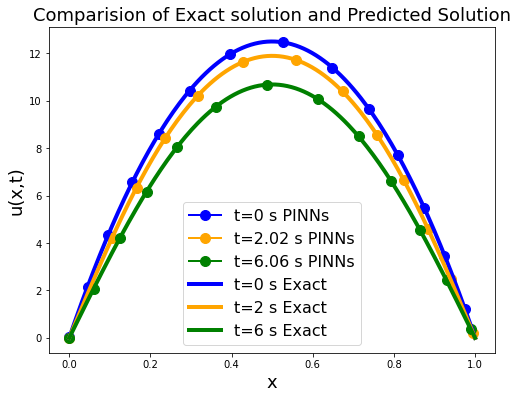

In [102]:
ax=plt.figure(figsize=(8,6))

plt.plot(x_value_0,u_value_t0,label="t=0 s PINNs",linewidth="2",color="b",marker="o",markevery=0.1,markersize=10)
plt.plot(x_value_2,u_value_t2,label="t=2.02 s PINNs",linewidth="2",color="orange",marker="o",markevery=0.1,markersize=10)
plt.plot(x_value_6,u_value_t6,label="t=6.06 s PINNs",linewidth="2",color="green",marker="o",markevery=0.1,markersize=10)
plt.plot(data_x,u0,linewidth="4",color='b',label="t=0 s Exact")
plt.plot(data_x,u2,linewidth="4",color='orange',label="t=2 s Exact")
plt.plot(data_x,u6,linewidth="4",color="green",label="t=6 s Exact")

plt.xlabel("x",fontsize=18)
plt.ylabel("u(x,t)",fontsize=18)
plt.title("Comparision of Exact solution and Predicted Solution",size=18)
plt.legend(fontsize=16)
#plt.savefig("heat_1d")
plt.show()
    

## Contour Plot

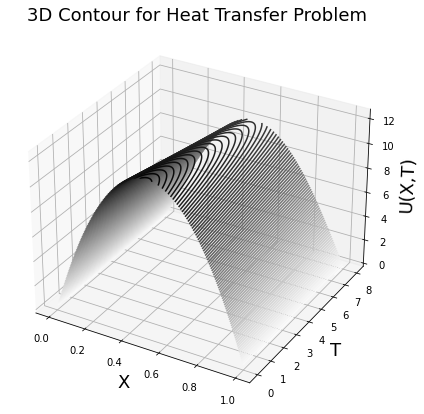

In [103]:
X_Contour=X_u_test[:,0][:,None]
#print(X_Contour.shape)
X_C=np.reshape(X_Contour,(200,100),order="F")

Y_Contour=X_u_test[:,1][:,None]
#print(Y_Contour.shape)
Y_C=np.reshape(Y_Contour,(200,100),order="F")

#u_pred.shape
U_Pred=np.reshape(u_pred,(200,100),order="F")

# Ploting 3D Contour 
fig = plt.figure(figsize=(7,7))
ax = plt.axes(projection='3d')
ax.contour3D(X_C, Y_C, U_Pred, 100, cmap='binary')
ax.set_xlabel('X',size=18)
ax.set_ylabel('T',size=18)
ax.set_zlabel('U(X,T)',size=18)
ax.set_title('3D Contour for Heat Transfer Problem',size=18)
plt.show()

## Relative error

In [104]:
# Relative error

error=0
sum_pred=0
for i in range(len(u_value_t0)):
    error+=((u0[i]-u_value_t0[i])**2)
    sum_pred+=(u0[i])**2


error_root=error**0.5/(sum_pred**0.5)
print("\n The Relative Error: ",error_root[-1])


 The Relative Error:  0.0007729536


---
---